In [1]:
import zipfile
from pathlib import Path

zip_path = "/content/cafe-20261021T122706Z-1-001.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Đã giải nén xong!")
print(list(Path("/content").rglob("train.csv"))[:10])

FileNotFoundError: [Errno 2] No such file or directory: '/content/cafe-20261021T122706Z-1-001.zip'

In [2]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/cafe")

train = pd.read_csv(DATA_DIR / "train.csv")
stores = pd.read_csv(DATA_DIR / "stores.csv")
weather = pd.read_csv(DATA_DIR / "weather.csv")
holidays = pd.read_csv(DATA_DIR / "holidays.csv")

for name, df in {
    "train": train,
    "stores": stores,
    "weather": weather,
    "holidays": holidays
}.items():
    print(f"\n===== {name.upper()} =====")
    print("Kích thước:", df.shape)
    display(df.head())


===== TRAIN =====
Kích thước: (26632, 4)


,date,store_id,is_promo,revenue
0,2024-01-01,S02,0,6.44
1,2024-01-01,S03,0,8.86
2,2024-01-01,S04,0,17.08
3,2024-01-01,S05,0,29.15
4,2024-01-01,S06,0,8.16



===== STORES =====
Kích thước: (45, 8)


,store_id,city,district,store_type,area_m2,seats,has_parking,open_date
0,S01,Ha Noi,Ba Dinh,university,149.0,62,1,2025-12-07
1,S02,Ha Noi,Thanh Xuan,residential,95.0,28,1,27/07/2022
2,S03,Ha Noi,Hai Ba Trung,office,120.0,38,0,12/03/2018
3,S04,Ha Noi,Tay Ho,street,101.0,41,0,17/04/2019
4,S05,Ha Noi,Hai Ba Trung,street,191.0,75,1,2020-12-24



===== WEATHER =====
Kích thước: (1593, 4)


,date,city,temp_c,rain_mm
0,2024-01-01,Ha Noi,15.9,0.0
1,2024-01-02,Ha Noi,17.5,0.0
2,2024-01-03,Ha Noi,15.2,0.0
3,2024-01-04,Ha Noi,20.0,0.0
4,2024-01-05,Ha Noi,14.0,0.0



===== HOLIDAYS =====
Kích thước: (55, 3)


,date,holiday_name,type
0,2024-01-01,New Year's Day,national_holiday
1,2024-02-03,Ong Cong Ong Tao (23 Tet),event
2,2024-02-08,Tet holiday,national_holiday
3,2024-02-09,Tet holiday,national_holiday
4,2024-02-10,Lunar New Year (Tet),national_holiday


===== THỐNG KÊ DOANH THU =====


,revenue
count,26632.000000
mean,51.343409
std,1015.877130
min,0.570000
50%,18.280000
90%,30.450000
95%,34.594500
99%,44.806900
99.9%,12434.390000
max,53600.000000


Số doanh thu thiếu: 0
Số doanh thu <= 0: 0
Số doanh thu > 1.000: 31
Doanh thu lớn nhất: 53600.0

===== DÒNG CÓ DOANH THU LỚN NHẤT =====


,date,store_id,is_promo,revenue
2139,2024-03-07,S12,1,53600.0


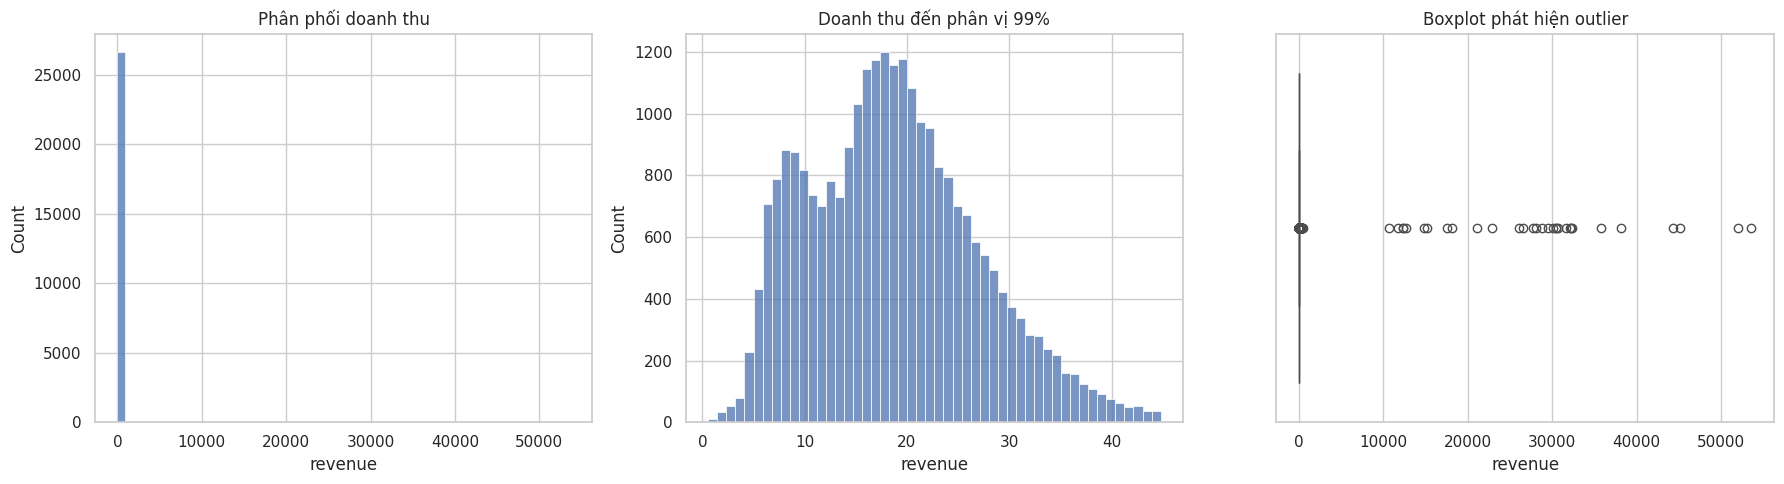

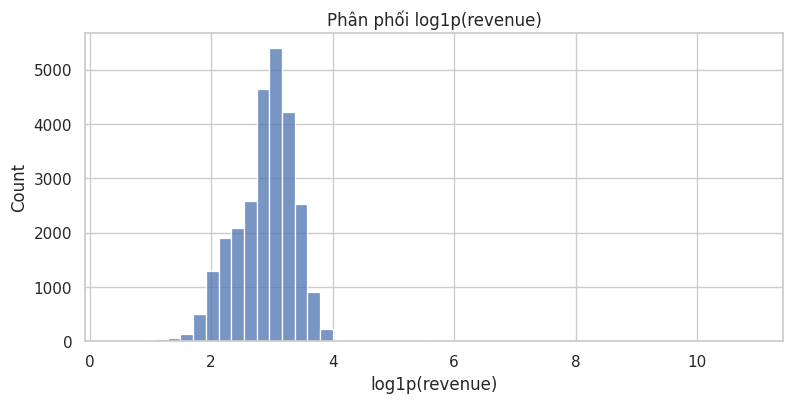

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")

# 1. Thống kê mô tả doanh thu
print("===== THỐNG KÊ DOANH THU =====")
display(train["revenue"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
).to_frame())

print("Số doanh thu thiếu:", train["revenue"].isna().sum())
print("Số doanh thu <= 0:", (train["revenue"] <= 0).sum())
print("Số doanh thu > 1.000:", (train["revenue"] > 1000).sum())
print("Doanh thu lớn nhất:", train["revenue"].max())

print("\n===== DÒNG CÓ DOANH THU LỚN NHẤT =====")
display(train.loc[[train["revenue"].idxmax()]])

# 2. Vẽ biểu đồ phân phối doanh thu
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=train, x="revenue", bins=60, ax=axes[0])
axes[0].set_title("Phân phối doanh thu")

p99 = train["revenue"].quantile(0.99)
sns.histplot(
    data=train[train["revenue"] <= p99],
    x="revenue",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Doanh thu đến phân vị 99%")

sns.boxplot(data=train, x="revenue", ax=axes[2])
axes[2].set_title("Boxplot phát hiện outlier")

plt.tight_layout()
plt.show()

# 3. Phân phối logarit để quan sát rõ hơn
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    np.log1p(train.loc[train["revenue"] >= 0, "revenue"]),
    bins=50,
    ax=ax
)
ax.set_title("Phân phối log1p(revenue)")
ax.set_xlabel("log1p(revenue)")
plt.show()

In [4]:
# ===== EDA 2: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU =====
import pandas as pd
import numpy as np

datasets = {
    "train": train,
    "stores": stores,
    "weather": weather,
    "holidays": holidays
}

# 1. Kiểm tra dữ liệu thiếu
for name, df in datasets.items():
    print(f"\n===== {name.upper()} =====")
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique()
    }))

# 2. Kiểm tra dữ liệu trùng
print("\n===== KIỂM TRA TRÙNG LẶP =====")
print("Train trùng date + store_id:",
      train.duplicated(["date", "store_id"]).sum())
print("Stores trùng store_id:",
      stores["store_id"].duplicated().sum())
print("Weather trùng date + city:",
      weather.duplicated(["date", "city"]).sum())
print("Holidays trùng date + holiday_name:",
      holidays.duplicated(["date", "holiday_name"]).sum())

# 3. Chuẩn hóa open_date
def parse_mixed_dates(values):
    s = values.astype("string").str.strip()
    iso = s.str.match(r"^\d{4}-\d{1,2}-\d{1,2}$", na=False)

    result = pd.Series(
        pd.NaT, index=values.index, dtype="datetime64[ns]"
    )
    result.loc[iso] = pd.to_datetime(
        s.loc[iso], format="%Y-%m-%d", errors="coerce"
    )
    result.loc[~iso] = pd.to_datetime(
        s.loc[~iso], dayfirst=True, errors="coerce"
    )
    return result

stores_clean = stores.copy()
stores_clean["open_date_raw"] = stores_clean["open_date"]
stores_clean["open_date"] = parse_mixed_dates(
    stores_clean["open_date_raw"]
)

print("\n===== OPEN_DATE SAU CHUẨN HÓA =====")
print("Ngày không chuyển đổi được:",
      stores_clean["open_date"].isna().sum())
display(stores_clean[
    ["store_id", "open_date_raw", "open_date"]
].head(15))

# 4. Chuẩn hóa ngày của các bảng
train_clean = train.copy()
train_clean["date"] = pd.to_datetime(
    train_clean["date"], errors="coerce"
)

weather_clean = weather.copy()
weather_clean["date"] = pd.to_datetime(
    weather_clean["date"], errors="coerce"
)

holidays_clean = holidays.copy()
holidays_clean["date"] = pd.to_datetime(
    holidays_clean["date"], errors="coerce"
)

print("\n===== PHẠM VI NGÀY =====")
print("Train:", train_clean["date"].min(),
      "->", train_clean["date"].max())
print("Weather:", weather_clean["date"].min(),
      "->", weather_clean["date"].max())
print("Holidays:", holidays_clean["date"].min(),
      "->", holidays_clean["date"].max())

print("\n===== KIỂM TRA GIÁ TRỊ =====")
print("is_promo không thuộc 0/1:",
      (~train_clean["is_promo"].isin([0, 1])).sum())
print("temp_c thiếu:", weather_clean["temp_c"].isna().sum())
print("rain_mm thiếu:", weather_clean["rain_mm"].isna().sum())
print("area_m2 thiếu:", stores_clean["area_m2"].isna().sum())
print("area_m2 <= 0:",
      (stores_clean["area_m2"] <= 0).sum())


===== TRAIN =====


,dtype,missing_count,missing_pct,unique_values
date,object,0,0.0,731
store_id,object,0,0.0,45
is_promo,int64,0,0.0,2
revenue,float64,0,0.0,3995



===== STORES =====


,dtype,missing_count,missing_pct,unique_values
store_id,object,0,0.00,45
city,object,0,0.00,2
district,object,0,0.00,19
store_type,object,0,0.00,9
area_m2,float64,2,4.44,36
seats,int64,0,0.00,31
has_parking,int64,0,0.00,2
open_date,object,0,0.00,44



===== WEATHER =====


...


===== HOLIDAYS =====


,dtype,missing_count,missing_pct,unique_values
date,object,0,0.0,53
holiday_name,object,0,0.0,15
type,object,0,0.0,2



===== KIỂM TRA TRÙNG LẶP =====
Train trùng date + store_id: 132
Stores trùng store_id: 0
Weather trùng date + city: 0
Holidays trùng date + holiday_name: 0

===== OPEN_DATE SAU CHUẨN HÓA =====
Ngày không chuyển đổi được: 0


,store_id,open_date_raw,open_date
0,S01,2025-12-07,2025-12-07
1,S02,27/07/2022,2022-07-27
2,S03,12/03/2018,2018-03-12
3,S04,17/04/2019,2019-04-17
4,S05,2020-12-24,2020-12-24
5,S06,2019-11-16,2019-11-16
6,S07,2025-06-10,2025-06-10
7,S08,2025-05-09,2025-05-09
8,S09,2025-02-10,2025-02-10
9,S10,2022-06-27,2022-06-27



===== PHẠM VI NGÀY =====
Train: 2024-01-01 00:00:00 -> 2025-12-31 00:00:00
Weather: 2024-01-01 00:00:00 -> 2026-03-31 00:00:00
Holidays: 2024-01-01 00:00:00 -> 2026-03-08 00:00:00

===== KIỂM TRA GIÁ TRỊ =====
is_promo không thuộc 0/1: 0
temp_c thiếu: 0
rain_mm thiếu: 16
area_m2 thiếu: 2
area_m2 <= 0: 0


Số dòng sau khi ghép: 26632
Số dòng ban đầu: 26632
Thiếu nhiệt độ: 878
Thiếu lượng mưa: 1122


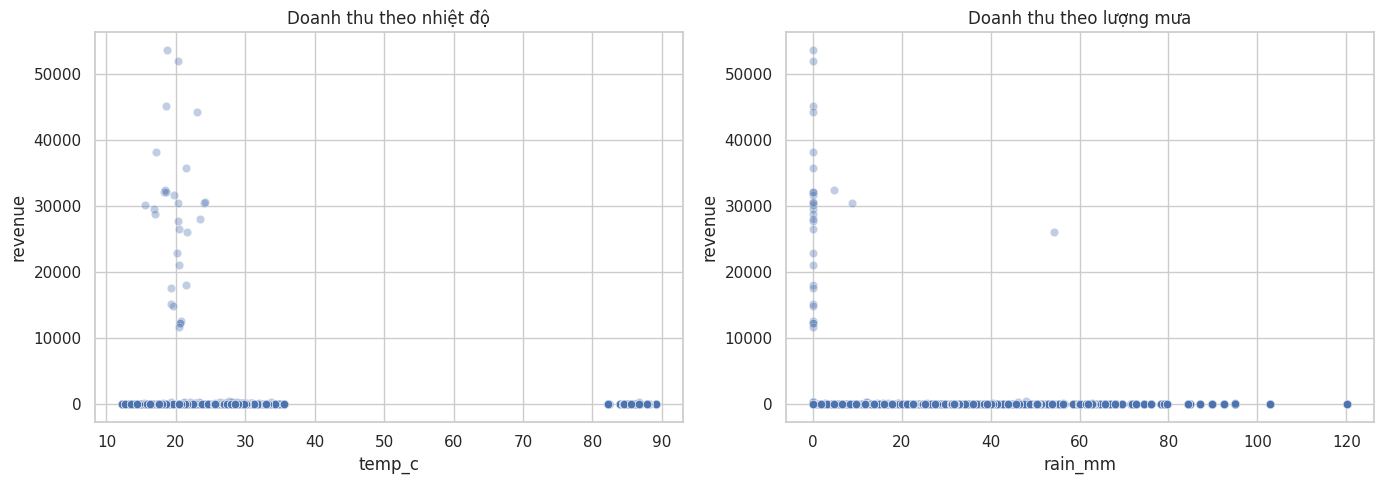

,count,mean,median,std
is_holiday,,,,
0,25307,51.31,18.35,1002.83
1,1325,52.06,15.85,1239.42


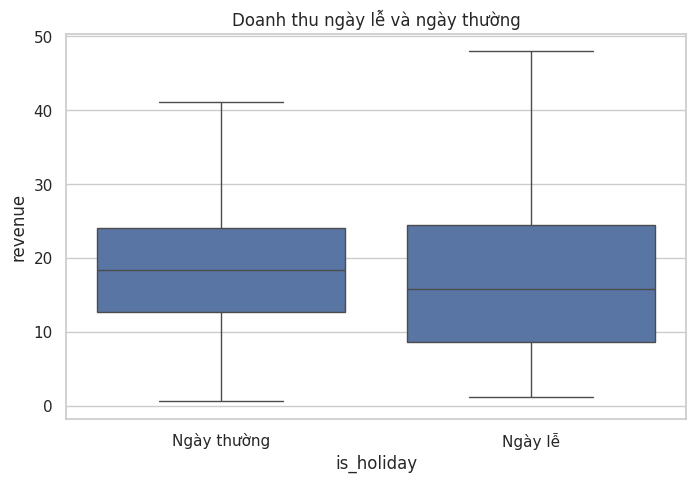

===== CÁC NGÀY TẾT 2026 =====


,date,holiday_name,type
43,2026-02-10,Ong Cong Ong Tao (23 Tet),event
44,2026-02-14,Tet holiday,national_holiday
46,2026-02-15,Tet holiday,national_holiday
47,2026-02-16,Tet holiday,national_holiday
48,2026-02-17,Lunar New Year (Tet),national_holiday
49,2026-02-18,Tet holiday,national_holiday
50,2026-02-19,Tet holiday,national_holiday
51,2026-02-20,Tet holiday,national_holiday
52,2026-02-21,Tet holiday,national_holiday
53,2026-02-22,Tet holiday,national_holiday


,count,mean,median
date,,,


In [5]:
# ===== EDA 3: THỜI TIẾT VÀ NGÀY LỄ =====
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Ghép doanh thu với cửa hàng
eda = train_clean.merge(
    stores_clean,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Ghép thời tiết theo ngày và thành phố
eda = eda.merge(
    weather_clean,
    on=["date", "city"],
    how="left",
    validate="many_to_one"
)

# Tổng hợp ngày lễ theo ngày để không nhân bản doanh thu
holiday_day = holidays_clean.groupby("date").agg(
    is_holiday=("holiday_name", "size"),
    holiday_names=(
        "holiday_name",
        lambda x: " | ".join(x.dropna().astype(str).unique())
    )
).reset_index()

eda = eda.merge(
    holiday_day,
    on="date",
    how="left",
    validate="many_to_one"
)
eda["is_holiday"] = eda["is_holiday"].fillna(0).gt(0).astype(int)

print("Số dòng sau khi ghép:", len(eda))
print("Số dòng ban đầu:", len(train_clean))
print("Thiếu nhiệt độ:", eda["temp_c"].isna().sum())
print("Thiếu lượng mưa:", eda["rain_mm"].isna().sum())

# 1. Doanh thu theo nhiệt độ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=eda, x="temp_c", y="revenue",
    alpha=0.35, ax=axes[0]
)
axes[0].set_title("Doanh thu theo nhiệt độ")

sns.scatterplot(
    data=eda, x="rain_mm", y="revenue",
    alpha=0.35, ax=axes[1]
)
axes[1].set_title("Doanh thu theo lượng mưa")

plt.tight_layout()
plt.show()

# 2. So sánh ngày lễ và ngày thường
display(
    eda.groupby("is_holiday")["revenue"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=eda, x="is_holiday", y="revenue",
    showfliers=False
)
plt.xticks([0, 1], ["Ngày thường", "Ngày lễ"])
plt.title("Doanh thu ngày lễ và ngày thường")
plt.show()

# 3. Tìm ngày Tết năm 2026 trong holidays.csv
tet_mask = holidays_clean["holiday_name"].str.contains(
    r"Tet|Tết|Lunar New Year",
    case=False, na=False
)

tet_2026 = holidays_clean[
    tet_mask & (holidays_clean["date"].dt.year == 2026)
].sort_values("date")

print("===== CÁC NGÀY TẾT 2026 =====")
display(tet_2026)

if not tet_2026.empty:
    tet_dates = tet_2026["date"].drop_duplicates()
    display(
        eda[eda["date"].isin(tet_dates)]
        .groupby("date")["revenue"]
        .agg(["count", "mean", "median"])
        .round(2)
    )
else:
    print("Không tìm thấy ngày Tết 2026 theo từ khóa trên.")